In [1]:
'''Evaluate machine learning models for bias and fairness, analyzing subgroup disparities and employing fairness metrics 
(e.g., demographic parity, equal opportunity) to ensure ethical and equitable model deployment'''

'Evaluate machine learning models for bias and fairness, analyzing subgroup disparities and employing fairness metrics \n(e.g., demographic parity, equal opportunity) to ensure ethical and equitable model deployment'

In [2]:
# importing required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

In [3]:
# loading dataset
df = pd.read_csv('global_pharmacy_sales_data.csv')
df.head()

,date,year,month,day,region,country,category,medicine,age_group,units_sold,unit_price,stock_level,expiry_days_remaining,covid_flag
0,2025-10-12,2025,10,12,Middle East,UAE,Chronic,Amlodipine,0-12,328,45.38,4774,466,0
1,2020-09-15,2020,9,15,South Asia,India,Chronic,Amlodipine,26-45,371,75.49,4584,181,1
2,2020-02-26,2020,2,26,Middle East,UAE,Vitamin,Vitamin C,0-12,948,22.51,3934,556,1
3,2025-11-09,2025,11,9,South Asia,Sri Lanka,Chronic,Amlodipine,0-12,275,63.29,4544,330,0
4,2022-04-04,2022,4,4,South America,Argentina,Chronic,Amlodipine,26-45,563,44.28,4284,590,0


In [4]:
# inspecting dataset shape and columns
print(df.shape)
print(df.columns.tolist())
print(df.info())

(177990, 14)
['date', 'year', 'month', 'day', 'region', 'country', 'category', 'medicine', 'age_group', 'units_sold', 'unit_price', 'stock_level', 'expiry_days_remaining', 'covid_flag']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 177990 entries, 0 to 177989
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   date                   177990 non-null  object 
 1   year                   177990 non-null  int64  
 2   month                  177990 non-null  int64  
 3   day                    177990 non-null  int64  
 4   region                 177990 non-null  object 
 5   country                177990 non-null  object 
 6   category               177990 non-null  object 
 7   medicine               177990 non-null  object 
 8   age_group              177990 non-null  object 
 9   units_sold             177990 non-null  int64  
 10  unit_price             177990 non-null  float64
 11  stock_lev

In [5]:
# checking summary statistics and missing values
print(df.isnull().sum())
print(df.describe())

date                     0
year                     0
month                    0
day                      0
region                   0
country                  0
category                 0
medicine                 0
age_group                0
units_sold               0
unit_price               0
stock_level              0
expiry_days_remaining    0
covid_flag               0
dtype: int64
                year          month            day     units_sold  \
count  177990.000000  177990.000000  177990.000000  177990.000000   
mean     2022.499702       6.521754      15.730457     447.913849   
std         1.708113       3.448703       8.801170     338.924528   
min      2020.000000       1.000000       1.000000      31.000000   
25%      2021.000000       4.000000       8.000000     284.000000   
50%      2023.000000       7.000000      16.000000     387.000000   
75%      2024.000000      10.000000      23.000000     529.000000   
max      2025.000000      12.000000      31.000000    870

In [6]:
# creating binary target variable and sensitive demographic subgroup
df['high_sales'] = (df['units_sold'] >= df['units_sold'].median()).astype(int)
df['is_elderly'] = (df['age_group'] == '65+').astype(int)
print(df['high_sales'].value_counts())
print(df['is_elderly'].value_counts())

high_sales
1    89217
0    88773
Name: count, dtype: int64
is_elderly
0    142254
1     35736
Name: count, dtype: int64


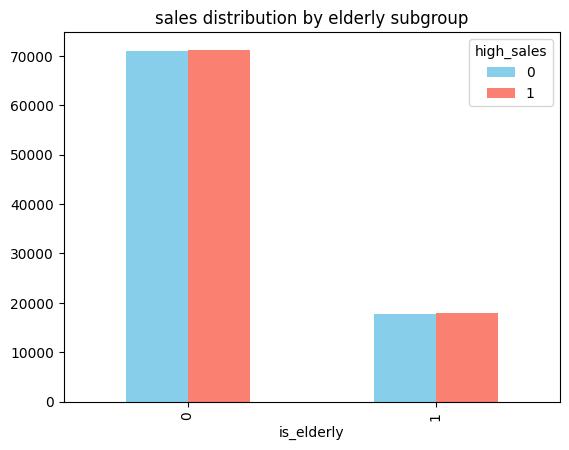

In [7]:
# plotting distribution of high sales across demographic subgroups
sales_by_age = df.groupby('is_elderly')['high_sales'].value_counts().unstack()
sales_by_age.plot(kind='bar', color=['skyblue', 'salmon'])
plt.title('sales distribution by elderly subgroup')
plt.show()

In [8]:
# preparing features and sensitive attribute for modeling
features = ['unit_price', 'stock_level', 'expiry_days_remaining', 'covid_flag', 'month']
sample_df = df.sample(n=10000, random_state=42).reset_index(drop=True)
X = sample_df[features]
y = sample_df['high_sales']
subgroup = sample_df['is_elderly']
print(X.head())

   unit_price  stock_level  expiry_days_remaining  covid_flag  month
0       53.07         4601                    342           0     11
1       79.53         4696                    524           0      7
2       49.82         4352                    677           0      5
3       64.46         4603                    198           1      9
4       87.59         4515                    224           0      7


In [9]:
# splitting dataset into training and testing sets
X_train, X_test, y_train, y_test, sub_train, sub_test = train_test_split(
    X, y, subgroup, test_size=0.25, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)

(7500, 5) (2500, 5)


In [10]:
# training classifier on training data
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
print('model trained successfully')

model trained successfully


In [11]:
# evaluating overall classification performance
print('accuracy:', accuracy_score(y_test, y_pred))
print('precision:', precision_score(y_test, y_pred))
print('recall:', recall_score(y_test, y_pred))
print('f1 score:', f1_score(y_test, y_pred))
print('confusion matrix:\n', confusion_matrix(y_test, y_pred))

accuracy: 0.8292
precision: 0.830249396621078
recall: 0.8269230769230769
f1 score: 0.8285828984343637
confusion matrix:
 [[1041  211]
 [ 216 1032]]


In [12]:
# evaluating performance disparities across subgroups
results_df = pd.DataFrame({'actual': y_test, 'predicted': y_pred, 'subgroup': sub_test})
for g in [0, 1]:
    sub = results_df[results_df['subgroup'] == g]
    acc = accuracy_score(sub['actual'], sub['predicted'])
    rec = recall_score(sub['actual'], sub['predicted'])
    prec = precision_score(sub['actual'], sub['predicted'])
    label = 'elderly (65+)' if g == 1 else 'non-elderly'
    print(f"{label} - accuracy: {acc:.4f}, recall (tpr): {rec:.4f}, precision: {prec:.4f}")

non-elderly - accuracy: 0.8296, recall (tpr): 0.8270, precision: 0.8337
elderly (65+) - accuracy: 0.8277, recall (tpr): 0.8264, precision: 0.8163


In [13]:
# calculating demographic parity difference and ratio
selection_rate_0 = (results_df[results_df['subgroup'] == 0]['predicted'] == 1).mean()
selection_rate_1 = (results_df[results_df['subgroup'] == 1]['predicted'] == 1).mean()
dp_difference = abs(selection_rate_1 - selection_rate_0)
dp_ratio = selection_rate_1 / selection_rate_0 if selection_rate_0 > 0 else 0
print(f"non-elderly selection rate: {selection_rate_0:.4f}")
print(f"elderly selection rate: {selection_rate_1:.4f}")
print(f"demographic parity difference: {dp_difference:.4f}")
print(f"demographic parity ratio (disparate impact): {dp_ratio:.4f}")

non-elderly selection rate: 0.5003
elderly selection rate: 0.4851
demographic parity difference: 0.0151
demographic parity ratio (disparate impact): 0.9698


In [14]:
# calculating equal opportunity metric
tpr_0 = recall_score(results_df[results_df['subgroup'] == 0]['actual'], results_df[results_df['subgroup'] == 0]['predicted'])
tpr_1 = recall_score(results_df[results_df['subgroup'] == 1]['actual'], results_df[results_df['subgroup'] == 1]['predicted'])
equal_opportunity_diff = abs(tpr_1 - tpr_0)
print(f"non-elderly tpr: {tpr_0:.4f}")
print(f"elderly tpr: {tpr_1:.4f}")
print(f"equal opportunity difference: {equal_opportunity_diff:.4f}")

non-elderly tpr: 0.8270
elderly tpr: 0.8264
equal opportunity difference: 0.0006


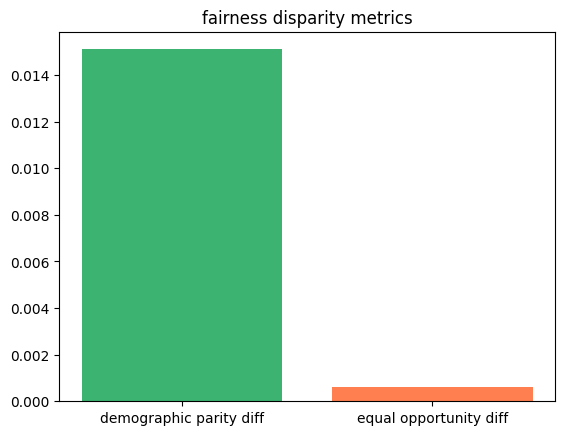

In [15]:
# plotting fairness metrics across demographic subgroups
plt.bar(['demographic parity diff', 'equal opportunity diff'], [dp_difference, equal_opportunity_diff], color=['mediumseagreen', 'coral'])
plt.title('fairness disparity metrics')
plt.show()

In [16]:
# summarizing subgroup fairness evaluation
fairness_summary = pd.DataFrame({
    'subgroup': ['non-elderly (0)', 'elderly (1)'],
    'selection_rate': [selection_rate_0, selection_rate_1],
    'tpr_recall': [tpr_0, tpr_1]
})
print(fairness_summary)

          subgroup  selection_rate  tpr_recall
0  non-elderly (0)        0.500251    0.827038
1      elderly (1)        0.485149    0.826446
